<a href="https://colab.research.google.com/github/weiiii/11510IPT-553000-Deep-Learning-in-Biomedical-Optical-Imaging/blob/main/114003805_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW3: Hyperparameter Tuning

This notebook trains a baseline classifier on the chest X-ray dataset to distinguish **NORMAL** from **PNEUMONIA** images.

It is organized as follows: import libraries → define training / validation / test functions → prepare data → build model → set hyperparameters and train → plot learning curves → evaluate on the test set.

Use this notebook as a starting point. You are free to modify any part of it (hyperparameters, model architecture, data augmentation, etc.) for your experiments, and summarize your findings in the analysis report.

# Import Library

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random
import time
import torch
import torch.nn as nn
import torch.optim as optims

from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms.functional import InterpolationMode

This cell sets up the computing device and checks whether a GPU is available. Training on a GPU is much faster than on a CPU.

In [ ]:
device = torch.device('cuda')
gpu_count = torch.cuda.device_count()

print("Using", gpu_count, "GPUs")
print("CUDA is available:", torch.cuda.is_available())

Using 1 GPUs
CUDA is available: True


This cell defines the three functions used throughout the homework:

- **`train_one_epoch`**: trains the model for one epoch on the training set (forward pass → loss → backpropagation → weight update) and returns the average loss and accuracy.
- **`val_one_epoch`**: evaluates the model on the validation set without updating weights, and saves the checkpoint with the best validation accuracy.
- **`evaluate`**: loads the saved best model and reports the final loss and accuracy on the test set.

In [ ]:
# train loop
def train_one_epoch(model, device, criterion, optimizer, train_data_loader):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.train()

    for batch_idx, (images, labels) in enumerate (train_data_loader):
        images = images.to(device)
        labels = labels.to(device).float()
        optimizer.zero_grad()
        preds = model(images)
        loss = criterion(preds, labels.unsqueeze(1))

        # Calculating Loss
        epoch_loss.append(loss.item())

        # Calculating Metrics
        predicts = (preds > 0.5).float()
        predicts = predicts.view(-1)
        predicts = predicts.detach().cpu().numpy()
        labels = labels.detach().cpu().numpy()
        acc = accuracy_score(labels, predicts)

        epoch_acc.append(acc)

        # Backpropagation
        loss.backward()
        optimizer.step()

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    return epoch_loss, epoch_acc, total_time

# validation loop
def val_one_epoch(model, device, criterion, val_data_loader, best_acc, save):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.eval()

    with torch.no_grad():
        for images, labels in val_data_loader:
            images = images.to(device)
            labels = labels.to(device).float()
            preds = model(images)

            # Calculating Loss
            loss = criterion(preds, labels.unsqueeze(1))
            epoch_loss.append(loss.item())

            # Calculating Metrics
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            epoch_acc.append(acc)

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    # Saving best model
    if epoch_acc > best_acc:
        best_acc = epoch_acc
        torch.save(model.state_dict(), f"{save}.pth")

    return epoch_loss, epoch_acc, total_time, best_acc

# evaluate loop (test loop)
def evaluate(model, device, model_path, test_loader):
    try:
        model.load_state_dict(torch.load(model_path))
        print("Model weights loaded successfully.")
    except Exception as e:
        print("Warning: Failed to load model weights. Using randomly initialized weights instead.")
        print(e)

    model.to(device)
    model.eval()

    test_loss = []
    test_acc = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device).float()

            # Forward pass
            preds = model(images)

            # Calculating loss
            loss = criterion(preds, labels.unsqueeze(1))
            test_loss.append(loss.item())

            # Calculating accuracy
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            test_acc.append(acc)

    # Overall test results
    avg_test_loss = np.mean(test_loss)
    avg_test_acc = np.mean(test_acc) * 100

    print(f"Test Accuracy: {avg_test_acc:.2f}%")
    print(f"Test Loss: {avg_test_loss:.4f}")

    return avg_test_loss, avg_test_acc

# Data Preparation

Mount Google Drive so the notebook can read the dataset stored in your Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


This cell prepares the data:

1. **Paths**: set the folders for the train / validation / test sets (change them to where you stored the dataset).
2. **Transforms**: resize every image to 256×256, convert it to a single grayscale channel, and turn it into a tensor. `train_transform` is applied only to the training set, so this is where data augmentation can be added.
3. **Datasets & DataLoaders**: `ImageFolder` labels each image by its folder name (NORMAL / PNEUMONIA), and `DataLoader` splits the data into batches.

In [ ]:
# define folder path for each set
data_root = '/content/drive/MyDrive/Colab Notebooks/Deep Learning in Biomedical Optical Imaging/chest_xray_HW3'

train_path = f'{data_root}/train'
val_path = f'{data_root}/val'
test_path = f'{data_root}/test'

# define transformation
train_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    #transforms.RandomRotation(degrees=5),###旋轉
    transforms.ToTensor(),
])

common_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

# create datasets
train_dataset = datasets.ImageFolder(train_path, transform=train_transform)
test_dataset = datasets.ImageFolder(test_path, transform=common_transform)
val_dataset = datasets.ImageFolder(val_path, transform=common_transform)

# create dataloaders
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

from collections import Counter

for split, dataset in [
    ("train", train_dataset),
    ("val", val_dataset),
    ("test", test_dataset),
]:
    counts = Counter(dataset.targets)
    print(split, {name: counts[i] for name, i in dataset.class_to_idx.items()})

train {'NORMAL': 1000, 'PNEUMONIA': 1000}
val {'NORMAL': 8, 'PNEUMONIA': 8}
test {'NORMAL': 234, 'PNEUMONIA': 390}


# Model

This cell builds the baseline model: a fully connected network (MLP) that flattens each image into a vector and passes it through three hidden layers (Linear → BatchNorm → ReLU → Dropout). The final Sigmoid outputs the probability of pneumonia for binary classification.

In [ ]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(256 * 256 * 1, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 1),
    nn.Sigmoid()
)

model.to(device)
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=65536, out_features=64, bias=True)
  (2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): ReLU()
  (4): Dropout(p=0.5, inplace=False)
  (5): Linear(in_features=64, out_features=64, bias=True)
  (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (7): ReLU()
  (8): Dropout(p=0.5, inplace=False)
  (9): Linear(in_features=64, out_features=64, bias=True)
  (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): ReLU()
  (12): Dropout(p=0.5, inplace=False)
  (13): Linear(in_features=64, out_features=1, bias=True)
  (14): Sigmoid()
)


# Model Model V2


In [ ]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((4, 4)),

    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(64 * 4 * 4, 1),
    nn.Sigmoid(),
).to(device)

print(model)

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): AdaptiveAvgPool2d(output_size=(4, 4))
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Dropout(p=0.5, inplace=False)
  (14): Linear(in_features=1024, out_features=1, bias=True)
  (15): Sigmoid()
)


# Loop

This cell sets the training hyperparameters: learning rate, weight decay, learning rate scheduler, number of epochs, optimizer, and loss function (binary cross-entropy). `save` is the file name for the best model checkpoint.

In [ ]:
# hyperparameter
lr = 0.001
weight_decay = 0.001

epochs = 10
optimizer = optims.AdamW(model.parameters(), lr=lr, weight_decay = weight_decay)
lr_scheduler = optims.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=5, mode='max')
criterion = nn.BCELoss()

# save checkpoint
#save 'HW3_MLP_baseline'
#save = 'C1_CNN'
#save = 'CNN_no_roation'
#save = 'CNN_lower_lr'
#save = 'CNN_adamw'
save = 'CNN_lower_lr_v2'

This cell runs the training loop. Each epoch trains on the training set, evaluates on the validation set, records the loss and accuracy, prints the results, and lets the learning rate scheduler adjust the learning rate based on the validation accuracy.

In [ ]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_acc = 0.0
output_list = []

for epoch in range(epochs):
    train_loss, train_acc, train_time = train_one_epoch(model, device, criterion, optimizer, train_loader)
    val_loss, val_acc, val_time, best_acc = val_one_epoch(model, device, criterion, val_loader, best_acc, save)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    total_time = train_time + val_time
    output_str = f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - train_acc: {train_acc:.2f}% - val_loss: {val_loss:.4f} - val_acc: {val_acc:.2f}% - time: {total_time:.2f}s"
    output_list.append(output_str)
    print(output_str)
    lr_scheduler.step(val_acc)

Epoch 1/10 - loss: 0.0881 - train_acc: 96.83% - val_loss: 2.0601 - val_acc: 56.25% - time: 55.07s
Epoch 2/10 - loss: 0.0814 - train_acc: 96.92% - val_loss: 0.7808 - val_acc: 62.50% - time: 55.21s
Epoch 3/10 - loss: 0.0772 - train_acc: 97.41% - val_loss: 1.5254 - val_acc: 56.25% - time: 55.10s
Epoch 4/10 - loss: 0.0731 - train_acc: 97.31% - val_loss: 0.6291 - val_acc: 75.00% - time: 55.41s
Epoch 5/10 - loss: 0.0630 - train_acc: 97.95% - val_loss: 1.9531 - val_acc: 56.25% - time: 55.21s
Epoch 6/10 - loss: 0.0616 - train_acc: 97.85% - val_loss: 1.6130 - val_acc: 50.00% - time: 55.25s
Epoch 7/10 - loss: 0.0659 - train_acc: 97.80% - val_loss: 0.5703 - val_acc: 75.00% - time: 55.09s
Epoch 8/10 - loss: 0.0645 - train_acc: 97.80% - val_loss: 2.2024 - val_acc: 56.25% - time: 55.59s
Epoch 9/10 - loss: 0.0555 - train_acc: 98.10% - val_loss: 0.9406 - val_acc: 62.50% - time: 55.20s
Epoch 10/10 - loss: 0.0513 - train_acc: 98.19% - val_loss: 1.2188 - val_acc: 56.25% - time: 55.24s


# Graph

This cell plots the training and validation loss and accuracy curves over epochs. Use them to check whether the model converges and whether it is overfitting or underfitting.

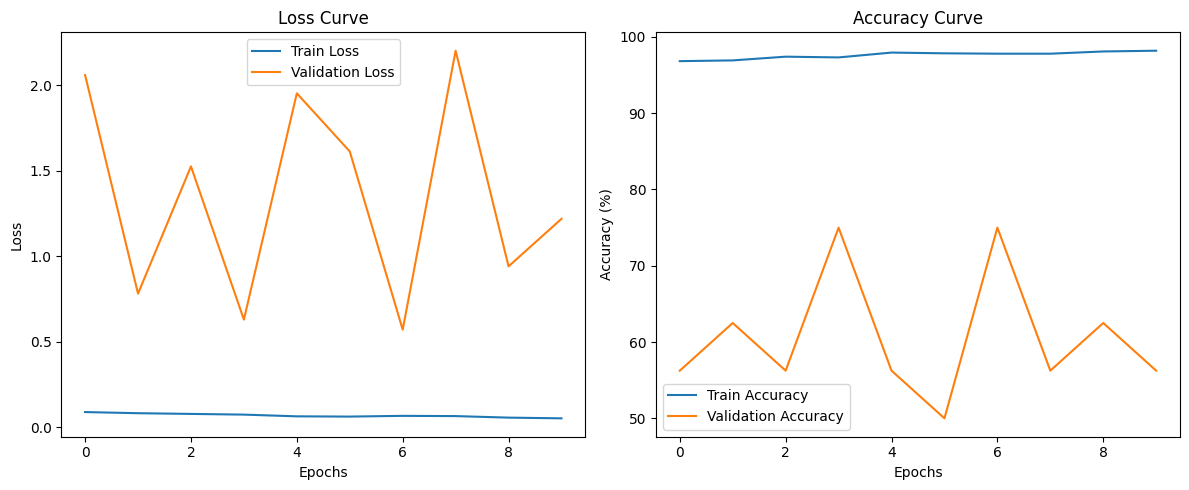

In [ ]:
plt.figure(figsize=(12, 5))

# loss graph
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# accuracy graph
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

# show
plt.tight_layout()
plt.show()

# Evaluate

This cell loads the best checkpoint saved during training and evaluates it on the test set, which the model has never seen, to report its final performance.

In [ ]:

from pathlib import Path
import shutil


model_path = 'model.pth'
avg_test_loss, avg_test_acc = evaluate(model, device, model_path, test_loader)


backup_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "Deep Learning in Biomedical Optical Imaging/HW3_MLP_baseline.pth"
)

shutil.copy2(model_path, backup_path)
print(f"已儲存 / Saved: {backup_path}")

avg_test_loss, avg_test_acc = evaluate(
    model, device, model_path, test_loader
)

[Errno 2] No such file or directory: 'model.pth'


KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import shutil

model_path = f"{save}.pth"

backup_dir = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "Deep Learning in Biomedical Optical Imaging"
)
backup_path = backup_dir / f"{save}.pth"

shutil.copy2(model_path, backup_path)
print(f"已儲存 / Saved: {backup_path}")

avg_test_loss, avg_test_acc = evaluate(
    model, device, model_path, test_loader
)

已儲存 / Saved: /content/drive/MyDrive/Colab Notebooks/Deep Learning in Biomedical Optical Imaging/CNN_adamw.pth
Model weights loaded successfully.
Test Accuracy: 76.25%
Test Loss: 0.7615


In [26]:
import torch, torch.nn as nn, math

d = "/content/drive/MyDrive/Colab Notebooks/Deep Learning in Biomedical Optical Imaging/"
names = ["HW3_MLP_baseline", "C1_CNN", "CNN_no_roation", "CNN_lower_lr", "CNN_adamw"]
BATCHES_PER_EPOCH = math.ceil(2000 / 64)   # = 32

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
        nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)),
        nn.Flatten(), nn.Dropout(0.5),
        nn.Linear(64 * 4 * 4, 1), nn.Sigmoid(),
    )

sds = {n: torch.load(d + n + ".pth", map_location="cpu") for n in names}

# ① 累計訓練了幾個 epoch
print("=== 累計訓練量（num_batches_tracked）===")
for n, sd in sds.items():
    nb = [v.item() for k, v in sd.items() if k.endswith("num_batches_tracked")][0]
    print(f"{n:18s} batches = {nb:5d}  → 累計 epoch ≈ {nb / BATCHES_PER_EPOCH:.1f}")

# ② CNN 之間的權重距離
def vec(sd):
    return torch.cat([v.flatten().float() for k, v in sd.items()
                      if k.endswith("weight") or k.endswith("bias")])

torch.manual_seed(42)
W = {"init(全新)": vec(make_cnn().state_dict())}
for n in names[1:]:
    W[n] = vec(sds[n])

print("\n=== 權重距離（越小越接近）===")
keys = list(W)
for i, a in enumerate(keys):
    for b in keys[i+1:]:
        print(f"{a:16s} ↔ {b:16s} {torch.norm(W[a] - W[b]).item():8.3f}")

=== 累計訓練量（num_batches_tracked）===
HW3_MLP_baseline   batches =    96  → 累計 epoch ≈ 3.0
C1_CNN             batches =   256  → 累計 epoch ≈ 8.0
CNN_no_roation     batches =   320  → 累計 epoch ≈ 10.0
CNN_lower_lr       batches =   416  → 累計 epoch ≈ 13.0
CNN_adamw          batches =   544  → 累計 epoch ≈ 17.0

=== 權重距離（越小越接近）===
init(全新)         ↔ C1_CNN              3.354
init(全新)         ↔ CNN_no_roation      3.450
init(全新)         ↔ CNN_lower_lr        3.553
init(全新)         ↔ CNN_adamw           4.073
C1_CNN           ↔ CNN_no_roation      1.607
C1_CNN           ↔ CNN_lower_lr        1.661
C1_CNN           ↔ CNN_adamw           2.109
CNN_no_roation   ↔ CNN_lower_lr        0.408
CNN_no_roation   ↔ CNN_adamw           1.185
CNN_lower_lr     ↔ CNN_adamw           1.036


train_transform = Compose(
    Resize(size=(256, 256), interpolation=bicubic, max_size=None, antialias=True)
    Grayscale(num_output_channels=1)
    ToTensor()
)

===== CNN_lower_lr_v2：adam, lr=0.0003, wd=0.001 =====
Epoch 1/10 - loss: 0.4877 - train_acc: 83.59% - val_loss: 0.9587 - val_acc: 50.00% - lr: 3e-04 - time: 56.13s
Epoch 2/10 - loss: 0.3248 - train_acc: 89.31% - val_loss: 1.3301 - val_acc: 50.00% - lr: 3e-04 - time: 55.49s
Epoch 3/10 - loss: 0.2619 - train_acc: 91.31% - val_loss: 0.5993 - val_acc: 56.25% - lr: 3e-04 - time: 55.51s
Epoch 4/10 - loss: 0.2141 - train_acc: 93.46% - val_loss: 0.4435 - val_acc: 81.25% - lr: 3e-04 - time: 55.49s
Epoch 5/10 - loss: 0.1890 - train_acc: 93.70% - val_loss: 0.5260 - val_acc: 68.75% - lr: 3e-04 - time: 55.31s
Epoch 6/10 - loss: 0.1790 - train_acc: 93.41% - val_loss: 0.5372 - val_acc: 68.75% - lr: 3e-04 - time: 55.46s
Epoch 7/10 - loss: 0.1556 - train_acc: 95.12% - val_loss: 0.5344 - val_acc: 75.00% - lr: 3e-04 - time: 55.46s
Epoch 8/10 -

/tmp/ipykernel_425/3172702070.py:73: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_425/3172702070.py:73: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E96}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_425/3172702070.py:74: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  plt.savefig(DRIVE / "HW3_sec2_compare.png", dpi=150)
/tmp/ipykernel_425/3172702070.py:74: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E96}) missing from font(s) DejaVu Sans.
  plt.savefig(DRIVE / "HW3_sec2_compare.png", dpi=150)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E9

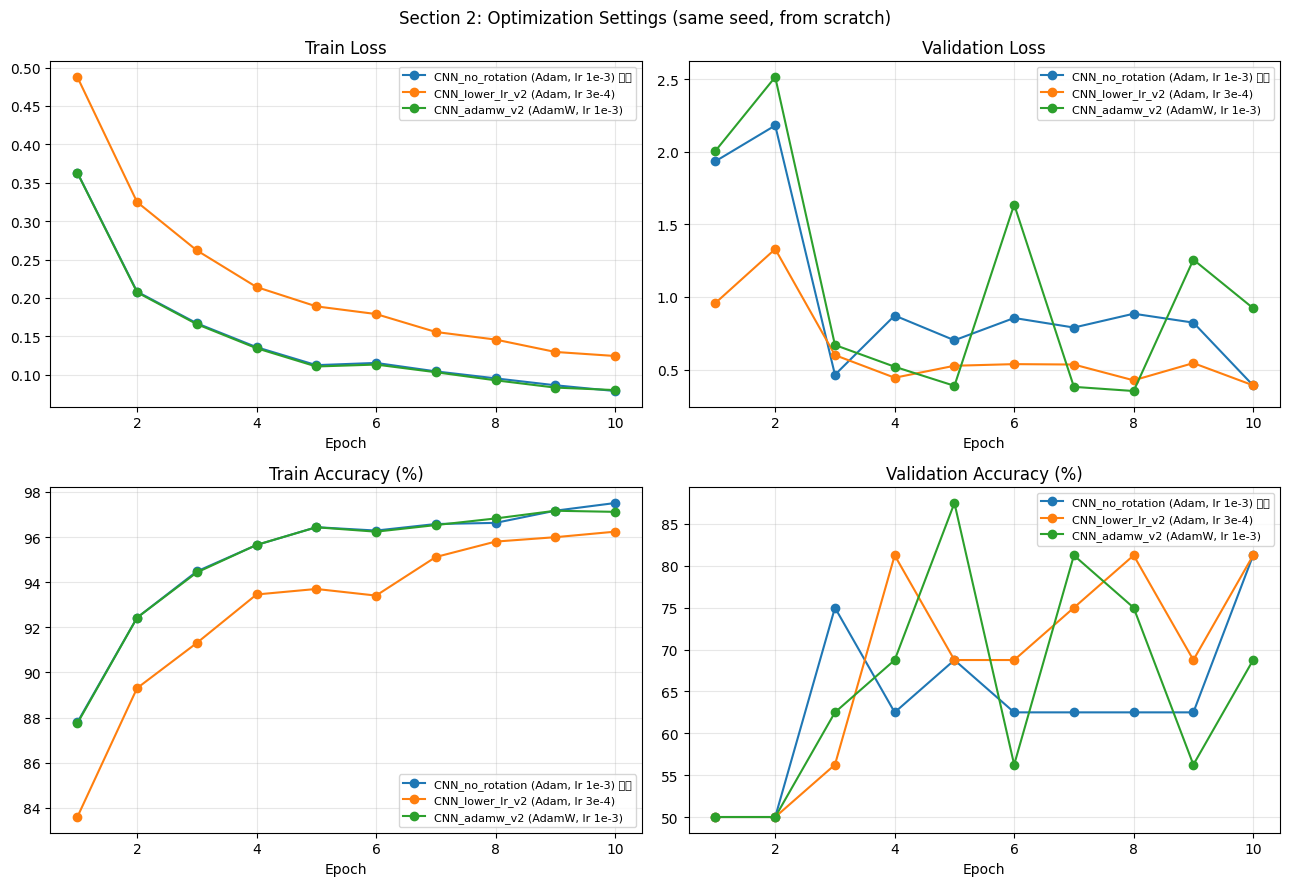


===== HW3 測試集總表（正確數 / 總張數；正類別 = PNEUMONIA）=====
             exp section              setting from_scratch  cum_epoch  params  test_acc  test_loss  sensitivity  specificity    AUC  TP  FN  TN  FP
HW3_MLP_baseline     1/4    MLP 基準, Adam 1e-3            ✅        3.0 4203137   83.8141     0.3727      94.3590      66.2393 0.9278 368  22 155  79
  CNN_no_roation       4    CNN 基準, Adam 1e-3            ✅       10.0   24545   86.3782     0.3268      95.8974      70.5128 0.9451 374  16 165  69
          C1_CNN       5         CNN + 旋轉 ±5°            ✅        8.0   24545   86.0577     0.3282      96.1538      69.2308 0.9457 375  15 162  72
 CNN_lower_lr_v2       2    CNN, Adam lr 3e-4            ✅        4.0   24545   87.6603     0.3245      86.6667      89.3162 0.9425 338  52 209  25
    CNN_adamw_v2       2   CNN, AdamW lr 1e-3            ✅        5.0   24545   86.3782     0.3180      94.6154      72.6496 0.9421 369  21 170  64
    CNN_lower_lr       3    接續訓練：基準 → lr 3e-4         ❌ 接續     

/tmp/ipykernel_425/3172702070.py:188: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_425/3172702070.py:188: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E96}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_425/3172702070.py:189: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  plt.savefig(DRIVE / "HW3_sec2_compare.png", dpi=150)
/tmp/ipykernel_425/3172702070.py:189: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E96}) missing from font(s) DejaVu Sans.
  plt.savefig(DRIVE / "HW3_sec2_compare.png", dpi=150)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH

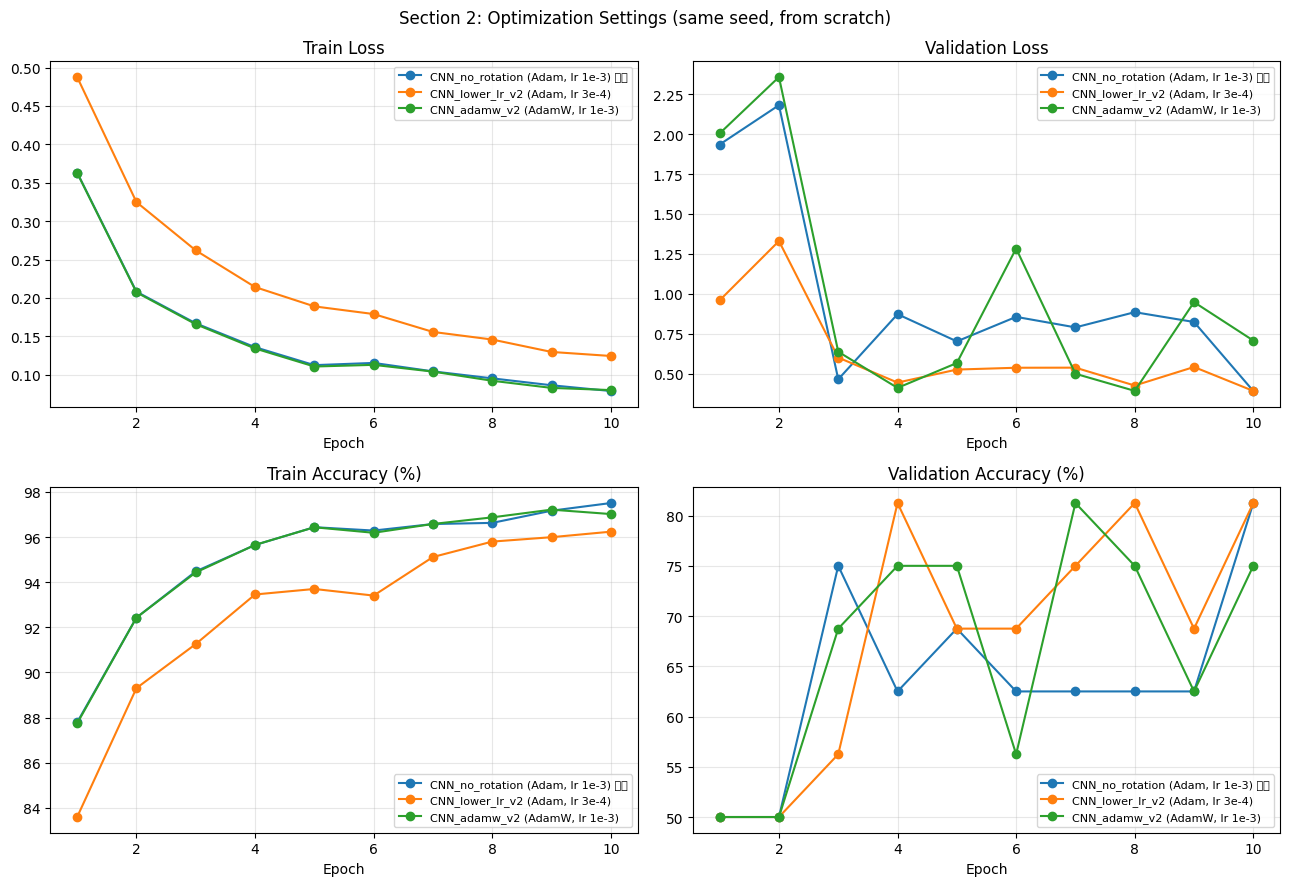


===== HW3 測試集總表（正確數 / 總張數；正類別 = PNEUMONIA）=====
             exp section              setting from_scratch  cum_epoch  params  test_acc  test_loss  sensitivity  specificity    AUC  TP  FN  TN  FP
HW3_MLP_baseline     1/4    MLP 基準, Adam 1e-3            ✅        3.0 4203137   83.8141     0.3727      94.3590      66.2393 0.9278 368  22 155  79
  CNN_no_roation       4    CNN 基準, Adam 1e-3            ✅       10.0   24545   86.3782     0.3268      95.8974      70.5128 0.9451 374  16 165  69
          C1_CNN       5         CNN + 旋轉 ±5°            ✅        8.0   24545   86.0577     0.3282      96.1538      69.2308 0.9457 375  15 162  72
 CNN_lower_lr_v2       2    CNN, Adam lr 3e-4            ✅        4.0   24545   87.6603     0.3244      86.6667      89.3162 0.9425 338  52 209  25
    CNN_adamw_v2       2   CNN, AdamW lr 1e-3            ✅        7.0   24545   84.2949     0.3576      89.2308      76.0684 0.9178 348  42 178  56
    CNN_lower_lr       3    接續訓練：基準 → lr 3e-4         ❌ 接續     

In [27]:
# ===================== HW3 最終實驗＋總表（一個 cell 跑完） =====================
# 需要先執行過：import、cell-6（三個函式）、掛載 Drive、cell-11（資料與 DataLoader）
import shutil, pandas as pd
from pathlib import Path
from sklearn.metrics import confusion_matrix, roc_auc_score

DRIVE = Path("/content/drive/MyDrive/Colab Notebooks/Deep Learning in Biomedical Optical Imaging")
EPOCHS = 10
criterion = nn.BCELoss()
print("train_transform =", train_transform)   # 確認沒有開旋轉

def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(256 * 256 * 1, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 1), nn.Sigmoid())

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)),
        nn.Flatten(), nn.Dropout(0.5), nn.Linear(64 * 4 * 4, 1), nn.Sigmoid())

# ---------- 1. 第 2 節：兩組從零開始的實驗 ----------
def run_exp(save, lr, opt_name, wd=1e-3):
    torch.manual_seed(42)
    model = make_cnn().to(device)                      # 每組都是全新模型
    Opt = {"adam": optims.Adam, "adamw": optims.AdamW}[opt_name]
    optimizer = Opt(model.parameters(), lr=lr, weight_decay=wd)
    sched = optims.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=5, mode='max')
    h = {"loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    best_acc = 0.0
    print(f"\n===== {save}：{opt_name}, lr={lr}, wd={wd} =====")
    for ep in range(EPOCHS):
        tl, ta, tt = train_one_epoch(model, device, criterion, optimizer, train_loader)
        vl, va, vt, best_acc = val_one_epoch(model, device, criterion, val_loader, best_acc, save)
        cur_lr = optimizer.param_groups[0]['lr']
        for k, v in zip(h, [tl, ta, vl, va, cur_lr]):
            h[k].append(v)
        print(f"Epoch {ep+1}/{EPOCHS} - loss: {tl:.4f} - train_acc: {ta:.2f}% - val_loss: {vl:.4f} "
              f"- val_acc: {va:.2f}% - lr: {cur_lr:.0e} - time: {tt+vt:.2f}s")
        if ep == 0 and ta > 92:
            print("⚠️ 第 1 個 epoch 準確率過高，請檢查是否接到舊權重")
        sched.step(va)
    shutil.copy2(f"{save}.pth", DRIVE / f"{save}.pth")
    return h

H = {
    "CNN_lower_lr_v2 (Adam, lr 3e-4)": run_exp("CNN_lower_lr_v2", 3e-4, "adam"),
    "CNN_adamw_v2 (AdamW, lr 1e-3)":   run_exp("CNN_adamw_v2", 1e-3, "adamw"),
}
# 基準 CNN_no_rotation 的紀錄（取自之前的輸出）
H = {"CNN_no_rotation (Adam, lr 1e-3) 基準": {
        "loss": [0.3632, 0.2081, 0.1669, 0.1358, 0.1124, 0.1153, 0.1043, 0.0952, 0.0862, 0.0787],
        "train_acc": [87.79, 92.43, 94.48, 95.65, 96.44, 96.29, 96.58, 96.63, 97.17, 97.51],
        "val_loss": [1.9350, 2.1814, 0.4639, 0.8720, 0.7015, 0.8551, 0.7892, 0.8845, 0.8231, 0.3905],
        "val_acc": [50, 50, 75, 62.5, 68.75, 62.5, 62.5, 62.5, 62.5, 81.25]}, **H}

# ---------- 2. 第 2 節比較圖 ----------
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for name, h in H.items():
    ep = range(1, len(h["loss"]) + 1)
    ax[0, 0].plot(ep, h["loss"], marker="o", label=name)
    ax[0, 1].plot(ep, h["val_loss"], marker="o", label=name)
    ax[1, 0].plot(ep, h["train_acc"], marker="o", label=name)
    ax[1, 1].plot(ep, h["val_acc"], marker="o", label=name)
for a, t in zip(ax.flat, ["Train Loss", "Validation Loss", "Train Accuracy (%)", "Validation Accuracy (%)"]):
    a.set_title(t); a.set_xlabel("Epoch"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.suptitle("Section 2: Optimization Settings (same seed, from scratch)")
plt.tight_layout()
plt.savefig(DRIVE / "HW3_sec2_compare.png", dpi=150)
plt.show()

# ---------- 3. 全部模型在測試集的總表（第 6 節用） ----------
@torch.no_grad()
def full_eval(model):
    model.eval()
    ys, ps, loss_sum = [], [], 0.0
    for x, y in test_loader:
        p = model(x.to(device)).view(-1)
        loss_sum += criterion(p, y.float().to(device)).item() * len(y)
        ys += y.tolist(); ps += p.cpu().tolist()
    pred = [int(p > 0.5) for p in ps]
    tn, fp, fn, tp = confusion_matrix(ys, pred, labels=[0, 1]).ravel()
    return dict(test_acc=100 * (tp + tn) / len(ys), test_loss=loss_sum / len(ys),
                sensitivity=100 * tp / (tp + fn), specificity=100 * tn / (tn + fp),
                AUC=roc_auc_score(ys, ps), TP=tp, FN=fn, TN=tn, FP=fp)

MODELS = [  # (存檔名, 建構函式, 章節, 說明, 是否從零開始)
    ("HW3_MLP_baseline", make_mlp, "1/4", "MLP 基準, Adam 1e-3", "✅"),
    ("CNN_no_roation",   make_cnn, "4",   "CNN 基準, Adam 1e-3", "✅"),
    ("C1_CNN",           make_cnn, "5",   "CNN + 旋轉 ±5°", "✅"),
    ("CNN_lower_lr_v2",  make_cnn, "2",   "CNN, Adam lr 3e-4", "✅"),
    ("CNN_adamw_v2",     make_cnn, "2",   "CNN, AdamW lr 1e-3", "✅"),
    ("CNN_lower_lr",     make_cnn, "3",   "接續訓練：基準 → lr 3e-4", "❌ 接續"),
    ("CNN_adamw",        make_cnn, "3",   "接續訓練：→ AdamW lr 1e-3", "❌ 接續"),
]
rows = []
for save, build, sec, desc, fresh in MODELS:
    m = build().to(device)
    sd = torch.load(DRIVE / f"{save}.pth", map_location=device)
    m.load_state_dict(sd)
    nb = [v.item() for k, v in sd.items() if k.endswith("num_batches_tracked")][0]
    rows.append(dict(exp=save, section=sec, setting=desc, from_scratch=fresh,
                     cum_epoch=round(nb / len(train_loader), 1),
                     params=sum(p.numel() for p in m.parameters()), **full_eval(m)))

df = pd.DataFrame(rows).round(4)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("\n===== HW3 測試集總表（正確數 / 總張數；正類別 = PNEUMONIA）=====")
print(df.to_string(index=False))
df.to_csv(DRIVE / "HW3_summary.csv", index=False, encoding="utf-8-sig")
print(f"\n已存：{DRIVE / 'HW3_summary.csv'}、{DRIVE / 'HW3_sec2_compare.png'}")# ===================== HW3 最終實驗＋總表（一個 cell 跑完） =====================
# 需要先執行過：import、cell-6（三個函式）、掛載 Drive、cell-11（資料與 DataLoader）
import shutil, pandas as pd
from pathlib import Path
from sklearn.metrics import confusion_matrix, roc_auc_score

DRIVE = Path("/content/drive/MyDrive/Colab Notebooks/Deep Learning in Biomedical Optical Imaging")
EPOCHS = 10
criterion = nn.BCELoss()
print("train_transform =", train_transform)   # 確認沒有開旋轉

def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(256 * 256 * 1, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 1), nn.Sigmoid())

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)),
        nn.Flatten(), nn.Dropout(0.5), nn.Linear(64 * 4 * 4, 1), nn.Sigmoid())

# ---------- 1. 第 2 節：兩組從零開始的實驗 ----------
def run_exp(save, lr, opt_name, wd=1e-3):
    torch.manual_seed(42)
    model = make_cnn().to(device)                      # 每組都是全新模型
    Opt = {"adam": optims.Adam, "adamw": optims.AdamW}[opt_name]
    optimizer = Opt(model.parameters(), lr=lr, weight_decay=wd)
    sched = optims.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=5, mode='max')
    h = {"loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    best_acc = 0.0
    print(f"\n===== {save}：{opt_name}, lr={lr}, wd={wd} =====")
    for ep in range(EPOCHS):
        tl, ta, tt = train_one_epoch(model, device, criterion, optimizer, train_loader)
        vl, va, vt, best_acc = val_one_epoch(model, device, criterion, val_loader, best_acc, save)
        cur_lr = optimizer.param_groups[0]['lr']
        for k, v in zip(h, [tl, ta, vl, va, cur_lr]):
            h[k].append(v)
        print(f"Epoch {ep+1}/{EPOCHS} - loss: {tl:.4f} - train_acc: {ta:.2f}% - val_loss: {vl:.4f} "
              f"- val_acc: {va:.2f}% - lr: {cur_lr:.0e} - time: {tt+vt:.2f}s")
        if ep == 0 and ta > 92:
            print("⚠️ 第 1 個 epoch 準確率過高，請檢查是否接到舊權重")
        sched.step(va)
    shutil.copy2(f"{save}.pth", DRIVE / f"{save}.pth")
    return h

H = {
    "CNN_lower_lr_v2 (Adam, lr 3e-4)": run_exp("CNN_lower_lr_v2", 3e-4, "adam"),
    "CNN_adamw_v2 (AdamW, lr 1e-3)":   run_exp("CNN_adamw_v2", 1e-3, "adamw"),
}
# 基準 CNN_no_rotation 的紀錄（取自之前的輸出）
H = {"CNN_no_rotation (Adam, lr 1e-3) 基準": {
        "loss": [0.3632, 0.2081, 0.1669, 0.1358, 0.1124, 0.1153, 0.1043, 0.0952, 0.0862, 0.0787],
        "train_acc": [87.79, 92.43, 94.48, 95.65, 96.44, 96.29, 96.58, 96.63, 97.17, 97.51],
        "val_loss": [1.9350, 2.1814, 0.4639, 0.8720, 0.7015, 0.8551, 0.7892, 0.8845, 0.8231, 0.3905],
        "val_acc": [50, 50, 75, 62.5, 68.75, 62.5, 62.5, 62.5, 62.5, 81.25]}, **H}

# ---------- 2. 第 2 節比較圖 ----------
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for name, h in H.items():
    ep = range(1, len(h["loss"]) + 1)
    ax[0, 0].plot(ep, h["loss"], marker="o", label=name)
    ax[0, 1].plot(ep, h["val_loss"], marker="o", label=name)
    ax[1, 0].plot(ep, h["train_acc"], marker="o", label=name)
    ax[1, 1].plot(ep, h["val_acc"], marker="o", label=name)
for a, t in zip(ax.flat, ["Train Loss", "Validation Loss", "Train Accuracy (%)", "Validation Accuracy (%)"]):
    a.set_title(t); a.set_xlabel("Epoch"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.suptitle("Section 2: Optimization Settings (same seed, from scratch)")
plt.tight_layout()
plt.savefig(DRIVE / "HW3_sec2_compare.png", dpi=150)
plt.show()

# ---------- 3. 全部模型在測試集的總表（第 6 節用） ----------
@torch.no_grad()
def full_eval(model):
    model.eval()
    ys, ps, loss_sum = [], [], 0.0
    for x, y in test_loader:
        p = model(x.to(device)).view(-1)
        loss_sum += criterion(p, y.float().to(device)).item() * len(y)
        ys += y.tolist(); ps += p.cpu().tolist()
    pred = [int(p > 0.5) for p in ps]
    tn, fp, fn, tp = confusion_matrix(ys, pred, labels=[0, 1]).ravel()
    return dict(test_acc=100 * (tp + tn) / len(ys), test_loss=loss_sum / len(ys),
                sensitivity=100 * tp / (tp + fn), specificity=100 * tn / (tn + fp),
                AUC=roc_auc_score(ys, ps), TP=tp, FN=fn, TN=tn, FP=fp)

MODELS = [  # (存檔名, 建構函式, 章節, 說明, 是否從零開始)
    ("HW3_MLP_baseline", make_mlp, "1/4", "MLP 基準, Adam 1e-3", "✅"),
    ("CNN_no_roation",   make_cnn, "4",   "CNN 基準, Adam 1e-3", "✅"),
    ("C1_CNN",           make_cnn, "5",   "CNN + 旋轉 ±5°", "✅"),
    ("CNN_lower_lr_v2",  make_cnn, "2",   "CNN, Adam lr 3e-4", "✅"),
    ("CNN_adamw_v2",     make_cnn, "2",   "CNN, AdamW lr 1e-3", "✅"),
    ("CNN_lower_lr",     make_cnn, "3",   "接續訓練：基準 → lr 3e-4", "❌ 接續"),
    ("CNN_adamw",        make_cnn, "3",   "接續訓練：→ AdamW lr 1e-3", "❌ 接續"),
]
rows = []
for save, build, sec, desc, fresh in MODELS:
    m = build().to(device)
    sd = torch.load(DRIVE / f"{save}.pth", map_location=device)
    m.load_state_dict(sd)
    nb = [v.item() for k, v in sd.items() if k.endswith("num_batches_tracked")][0]
    rows.append(dict(exp=save, section=sec, setting=desc, from_scratch=fresh,
                     cum_epoch=round(nb / len(train_loader), 1),
                     params=sum(p.numel() for p in m.parameters()), **full_eval(m)))

df = pd.DataFrame(rows).round(4)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("\n===== HW3 測試集總表（正確數 / 總張數；正類別 = PNEUMONIA）=====")
print(df.to_string(index=False))
df.to_csv(DRIVE / "HW3_summary.csv", index=False, encoding="utf-8-sig")
print(f"\n已存：{DRIVE / 'HW3_summary.csv'}、{DRIVE / 'HW3_sec2_compare.png'}")